# Tesla and GameStop: Share Price vs. Revenue

Final project for the [IBM Data Science Professional Certificate](https://www.coursera.org/professional-certificates/ibm-data-science) on Coursera (course: *Python Project for Data Science*).

In this notebook I:

1. Download the full daily share price history of Tesla (TSLA) and GameStop (GME) with the `yfinance` API.
2. Scrape quarterly revenue tables from web pages with `requests` and `BeautifulSoup`.
3. Clean the revenue data with `pandas` (remove `$` signs and commas, drop empty rows, convert to numbers).
4. Plot share price against revenue with `plotly` and compare how they moved up to June 2021.

**Author:** Ghazal Ashraf

## Contents

- Setup and graphing function
- 1. Tesla share price
- 2. Tesla quarterly revenue (web scraping)
- 3. GameStop share price
- 4. GameStop quarterly revenue (web scraping)
- 5. Tesla: share price vs. revenue
- 6. GameStop: share price vs. revenue
- Key findings

## Setup

Install the packages listed in [`requirements.txt`](../requirements.txt) before running this notebook:

```
pip install -r requirements.txt
```

In [4]:
import yfinance as yf
import pandas as pd
import requests
from bs4 import BeautifulSoup
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import warnings

# Ignore FutureWarning messages from the libraries
warnings.filterwarnings("ignore", category=FutureWarning)

## Graphing function

`make_graph` takes a dataframe of share prices (with `Date` and `Close` columns), a dataframe of revenue (with `Date` and `Revenue` columns) and the company name. It draws share price and revenue as two stacked charts, up to June 2021.

This function was provided with the IBM lab. I fixed a typo in its date filter and removed an outdated `pandas` argument.

In [6]:
def make_graph(stock_data, revenue_data, stock):
    fig = make_subplots(rows=2, cols=1, shared_xaxes=True, subplot_titles=("Historical Share Price", "Historical Revenue"), vertical_spacing = .3)
    stock_data_specific = stock_data[stock_data.Date <= '2021-06-14']
    revenue_data_specific = revenue_data[revenue_data.Date <= '2021-04-30']
    fig.add_trace(go.Scatter(x=pd.to_datetime(stock_data_specific.Date), y=stock_data_specific.Close.astype("float"), name="Share Price"), row=1, col=1)
    fig.add_trace(go.Scatter(x=pd.to_datetime(revenue_data_specific.Date), y=revenue_data_specific.Revenue.astype("float"), name="Revenue"), row=2, col=1)
    fig.update_xaxes(title_text="Date", row=1, col=1)
    fig.update_xaxes(title_text="Date", row=2, col=1)
    fig.update_yaxes(title_text="Price ($US)", row=1, col=1)
    fig.update_yaxes(title_text="Revenue ($US Millions)", row=2, col=1)
    fig.update_layout(showlegend=False,
    height=900,
    title=stock,
    xaxis_rangeslider_visible=True)
    fig.show()

## 1. Tesla share price

Create a `Ticker` object for Tesla (`TSLA`), download its full price history with `history(period="max")`, and move the date from the index into a `Date` column.

In [10]:
tesla = yf.Ticker("TSLA")
tesla_data = tesla.history(period="max")
tesla_data.reset_index(inplace=True)
tesla_data.head()

,Date,Open,High,Low,Close,Volume,Dividends,Stock Splits
0,2010-06-29,1.266667,1.666667,1.169333,1.592667,281494500,0,0.0
1,2010-06-30,1.719333,2.028000,1.553333,1.588667,257806500,0,0.0
2,2010-07-01,1.666667,1.728000,1.351333,1.464000,123282000,0,0.0
3,2010-07-02,1.533333,1.540000,1.247333,1.280000,77097000,0,0.0
4,2010-07-06,1.333333,1.333333,1.055333,1.074000,103003500,0,0.0


## 2. Tesla quarterly revenue (web scraping)

Download the revenue page with `requests` and parse it with `BeautifulSoup`.

In [40]:
url = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-PY0220EN-SkillsNetwork/labs/project/revenue.htm"
html_data = requests.get(url).text

soup = BeautifulSoup(html_data, "html.parser")
soup.find_all('title')

[<title>Tesla Revenue 2010-2022 | TSLA | MacroTrends</title>]

Find the *Tesla Quarterly Revenue* table and keep the date and revenue from each row. Then drop quarters with no revenue figure and convert revenue (in US$ millions) to numbers.

In [46]:
rows = []

for table in soup.find_all('table'):
    if 'Tesla Quarterly Revenue' in table.find('th').text:
        for row in table.find_all('tr'):
            col = row.find_all('td')
            # Header rows have no <td> cells, so skip them
            if len(col) >= 2:
                date = col[0].text
                revenue = col[1].text.replace(',', '').replace('$', '')
                rows.append({"Date": date, "Revenue": revenue})

tesla_revenue = pd.DataFrame(rows, columns=['Date', 'Revenue'])

# Drop quarters with no revenue figure, then convert revenue to numbers
tesla_revenue = tesla_revenue[tesla_revenue['Revenue'] != ""].copy()
tesla_revenue["Revenue"] = pd.to_numeric(tesla_revenue["Revenue"])

tesla_revenue.tail()

,Date,Revenue
48,2010-09-30,31
49,2010-06-30,28
50,2010-03-31,21
52,2009-09-30,46
53,2009-06-30,27


## 3. GameStop share price

Same steps as for Tesla, using the GameStop ticker (`GME`).

In [49]:
gme = yf.Ticker("GME")
gme_data = gme.history(period="max")
gme_data.reset_index(inplace=True)
gme_data.head()

,Date,Open,High,Low,Close,Volume,Dividends,Stock Splits
0,2002-02-13,1.620128,1.693350,1.603296,1.691666,76216000,0.0,0.0
1,2002-02-14,1.712707,1.716074,1.670626,1.683250,11021600,0.0,0.0
2,2002-02-15,1.683251,1.687459,1.658002,1.674834,8389600,0.0,0.0
3,2002-02-19,1.666418,1.666418,1.578047,1.607504,7410400,0.0,0.0
4,2002-02-20,1.615921,1.662210,1.603296,1.662210,6892800,0.0,0.0


## 4. GameStop quarterly revenue (web scraping)

In [53]:
url = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-PY0220EN-SkillsNetwork/labs/project/stock.html"
html_data = requests.get(url).text

soup = BeautifulSoup(html_data, "html.parser")
soup.find_all('title')

[<title>GameStop Revenue 2006-2020 | GME | MacroTrends</title>]

The quarterly revenue table is the second `<tbody>` on the page. Clean it the same way as the Tesla data.

In [57]:
rows = []

for row in soup.find_all("tbody")[1].find_all("tr"):
    col = row.find_all("td")
    date = col[0].text
    revenue = col[1].text.replace("$", "").replace(",", "")
    rows.append({"Date": date, "Revenue": revenue})

gme_revenue = pd.DataFrame(rows, columns=['Date', 'Revenue'])

# Drop quarters with no revenue figure, then convert revenue to numbers
gme_revenue = gme_revenue[gme_revenue['Revenue'] != ""].copy()
gme_revenue["Revenue"] = pd.to_numeric(gme_revenue["Revenue"])

gme_revenue.tail()

,Date,Revenue
57,2006-01-31,1667
58,2005-10-31,534
59,2005-07-31,416
60,2005-04-30,475
61,2005-01-31,709


## 5. Tesla: share price vs. revenue

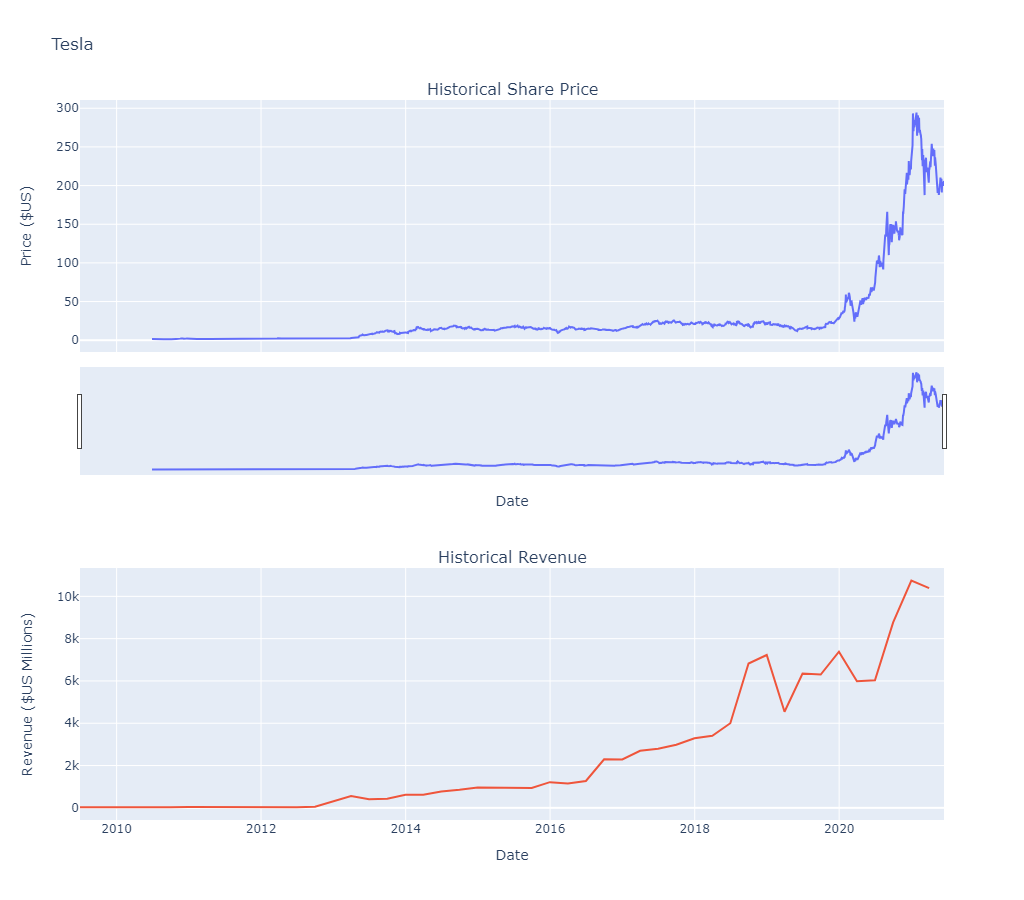

In [58]:
make_graph(tesla_data, tesla_revenue, 'Tesla')

## 6. GameStop: share price vs. revenue

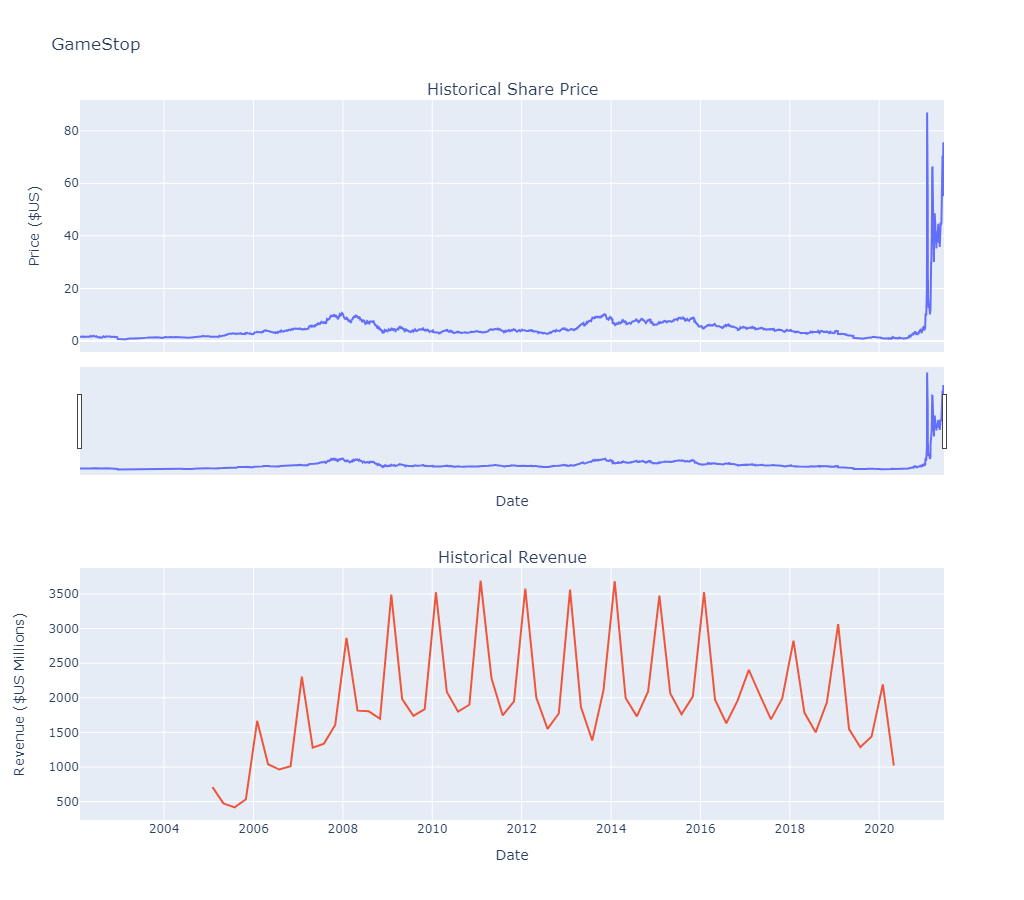

In [59]:
make_graph(gme_data, gme_revenue, 'GameStop')

## Key findings

Prices are daily closing prices from Yahoo Finance, adjusted for later stock splits. Revenue figures are in millions of US dollars (USD).

- **Tesla's share price grew much faster than its revenue in 2020.** Annual revenue rose 28% (from USD 24,578M in 2019 to USD 31,536M in 2020), while the share price rose about 8.4 times (from USD 27.89 at the end of 2019 to USD 235.22 at the end of 2020).
- **GameStop's revenue was shrinking for years before 2021.** Yearly revenue peaked at USD 9,551M in fiscal 2011 and fell to USD 6,467M in fiscal 2019. The share price fell with it, to a low of USD 0.70 in April 2020.
- **GameStop's January 2021 jump was not driven by revenue.** The share price went from USD 4.99 on 12 January 2021 to USD 86.88 on 27 January 2021, about 17 times higher in two weeks, during the short squeeze.
- **GameStop's revenue is highly seasonal.** In every fiscal year in the data, the quarter that includes the holiday season (ending in January) brings in the most revenue.

## Credits

This notebook is based on the *Extracting and Visualizing Stock Data* lab by IBM Skills Network (authors: Joseph Santarcangelo and Azim Hirjani), part of the IBM Data Science Professional Certificate. The lab instructions and the `make_graph` function are © IBM Corporation 2020.